In [17]:
import pandas as pd

In [2]:
df = pd.read_csv("../Data/auto-mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,name
393,27.0,4,140.0,86.00,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.00,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.00,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.00,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.00,2720.0,19.4,82,1,chevy s-10


### 자동차 연비 DataSet
- mpg(miles per galon) : 연비 / kpl(kilometer per liter)
- cyinders : 실린더 수
- displacement : 배기량
- horsepower : 마력, 출력
- weight : 차중
- acceleration : 가속능력
- model year : 출시연도
- origin : 제조국 (1: USA, 2: EU, 3: JPN)
- name : 모델명

In [4]:
# df의 외형 크기
df.shape

(398, 9)

In [ ]:
# df의 내부 구조
df.info()

# horsepower type이 str로 되어 있음 -> 데이터 중 str type이 껴있음

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 36.3 KB


In [6]:
df.mpg.dtypes

dtype('float64')

In [ ]:
# 데이터프레임의 기술 통계 정보(숫자 데이터만)
df.describe()

# mean(평균값)과 50%(중앙값)의 차이 확인하기 -> min,max를 본 후 차이가 큰지 안큰지 확인

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [ ]:
# # 데이터프레임의 기술 통계 정보(모든 데이터)
df.describe(include='all')

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,name
count,398.000000,398.000000,398.000000,398,398.000000,398.000000,398.000000,398.000000,398
unique,NaN,NaN,NaN,94,NaN,NaN,NaN,NaN,305
top,NaN,NaN,NaN,150.0,NaN,NaN,NaN,NaN,ford pinto
freq,NaN,NaN,NaN,22,NaN,NaN,NaN,NaN,6
mean,23.514573,5.454774,193.425879,NaN,2970.424623,15.568090,76.010050,1.572864,NaN
std,7.815984,1.701004,104.269838,NaN,846.841774,2.757689,3.697627,0.802055,NaN
min,9.000000,3.000000,68.000000,NaN,1613.000000,8.000000,70.000000,1.000000,NaN
25%,17.500000,4.000000,104.250000,NaN,2223.750000,13.825000,73.000000,1.000000,NaN
50%,23.000000,4.000000,148.500000,NaN,2803.500000,15.500000,76.000000,1.000000,NaN
75%,29.000000,8.000000,262.000000,NaN,3608.000000,17.175000,79.000000,2.000000,NaN


- unique : 중복을 제거한 종류의 수
- top : 가장 많은 빈도수를 갖는 변수
- freq : top에 해당하는 변수의 빈도수

In [ ]:
# origin : 제조국 (1: USA, 2: EU, 3: JPN)
df.origin.unique()  # 해당 column에 data가 어떤 종류가 있는지 먼저 확인
df.origin.value_counts() # 빈도수도 포함

# 데이터 갯수가 비슷해야 비교분석을 할 수 있다.
# 아래 경우에는 비교할 수 없는 데이터 기준
# confusion matrix : 혼동 행렬

origin
1    249
3     79
2     70
Name: count, dtype: int64

In [14]:
# 평균
print(df.mean(numeric_only=True))
print(df['mpg'].mean())
print(df.mpg.mean())
print(df[['mpg', 'weight']].mean())

mpg               23.514573
cylinders          5.454774
displacement     193.425879
weight          2970.424623
acceleration      15.568090
model year        76.010050
origin             1.572864
dtype: float64
23.514572864321607
23.514572864321607
mpg         23.514573
weight    2970.424623
dtype: float64


In [15]:
# 중앙값
print(df.median(numeric_only=True))
print(df['mpg'].median())
print(df.mpg.median())
print(df[['mpg', 'weight']].median())

mpg               23.0
cylinders          4.0
displacement     148.5
weight          2803.5
acceleration      15.5
model year        76.0
origin             1.0
dtype: float64
23.0
23.0
mpg         23.0
weight    2803.5
dtype: float64


----
#### 상관계수
0 ~ 0.3     : 상관 없음   
0.3 ~ 0.5   : 약간의 상관이 있음   
0.5 ~ 0.7   : 상관 있음   
0.7 ~       : 상관이 대부분임   

In [16]:
df.corr(numeric_only=True)

,mpg,cylinders,displacement,weight,acceleration,model year,origin
mpg,1.000000,-0.775396,-0.804203,-0.831741,0.420289,0.579267,0.563450
cylinders,-0.775396,1.000000,0.950721,0.896017,-0.505419,-0.348746,-0.562543
displacement,-0.804203,0.950721,1.000000,0.932824,-0.543684,-0.370164,-0.609409
weight,-0.831741,0.896017,0.932824,1.000000,-0.417457,-0.306564,-0.581024
acceleration,0.420289,-0.505419,-0.543684,-0.417457,1.000000,0.288137,0.205873
model year,0.579267,-0.348746,-0.370164,-0.306564,0.288137,1.000000,0.180662
origin,0.563450,-0.562543,-0.609409,-0.581024,0.205873,0.180662,1.000000


----
#### Pandas 내장 그래프 도구

In [29]:
df = pd.read_excel("../Data/남북한발전전력량_2023.xlsx")
df

,전력량 (억㎾h),발전 전력별,1990,1991,1992,1993,1994,1995,1996,1997,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,남한,합계,1077,1186,1310,1444,1650,1847,2055,2244,...,5220,5281,5404,5535,5706,5630,5522,5768,5901,5880
1,NaN,수력,64,51,49,60,41,55,52,54,...,78,58,66,70,73,64,69,67,66,73
2,NaN,화력,484,573,696,803,1022,1122,1264,1420,...,3427,3402,3523,3745,3908,3756,3467,3618,3607,3471
3,NaN,원자력,529,563,565,581,587,670,739,771,...,1564,1648,1620,1484,1335,1459,1602,1580,1761,1805
4,NaN,신재생,-,-,-,-,-,-,-,-,...,151,173,195,236,290,351,384,503,467,531
5,북한,합계,277,263,247,221,231,230,213,193,...,216,190,239,235,249,238,239,255,264,250
6,NaN,수력,156,150,142,133,138,142,125,107,...,130,100,128,117,142,137,128,161,166,158
7,NaN,화력,121,113,105,88,93,88,88,86,...,86,90,111,118,107,101,111,94,98,92
8,NaN,원자력,-,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-


In [26]:
df.columns

Index(['전력량 (억㎾h)',    '발전 전력별',        1990,        1991,        1992,
              1993,        1994,        1995,        1996,        1997,
              1998,        1999,        2000,        2001,        2002,
              2003,        2004,        2005,        2006,        2007,
              2008,        2009,        2010,        2011,        2012,
              2013,        2014,        2015,        2016,        2017,
              2018,        2019,        2020,        2021,        2022,
              2023],
      dtype='object')

In [30]:
# 남한과 북한의 발전량 합계 데이터만 추출
df_sn = df.loc[[0,5],1990:]
df_sn.index = ['South', 'North']
df_sn

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
South,1077,1186,1310,1444,1650,1847,2055,2244,2153,2393,...,5220,5281,5404,5535,5706,5630,5522,5768,5901,5880
North,277,263,247,221,231,230,213,193,170,186,...,216,190,239,235,249,238,239,255,264,250


In [34]:
df_sn.info()

<class 'pandas.DataFrame'>
Index: 2 entries, South to North
Data columns (total 34 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   1990    2 non-null      object
 1   1991    2 non-null      object
 2   1992    2 non-null      object
 3   1993    2 non-null      object
 4   1994    2 non-null      object
 5   1995    2 non-null      object
 6   1996    2 non-null      object
 7   1997    2 non-null      object
 8   1998    2 non-null      object
 9   1999    2 non-null      object
 10  2000    2 non-null      object
 11  2001    2 non-null      object
 12  2002    2 non-null      object
 13  2003    2 non-null      object
 14  2004    2 non-null      object
 15  2005    2 non-null      object
 16  2006    2 non-null      object
 17  2007    2 non-null      object
 18  2008    2 non-null      object
 19  2009    2 non-null      object
 20  2010    2 non-null      object
 21  2011    2 non-null      object
 22  2012    2 non-null      object
 23  20

> 모든 데이터가 Object로 되어 있다.

In [35]:
# object -> int로 변환
df_sn = df_sn.astype('int')

In [36]:
df_sn.info()

<class 'pandas.DataFrame'>
Index: 2 entries, South to North
Data columns (total 34 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   1990    2 non-null      int64
 1   1991    2 non-null      int64
 2   1992    2 non-null      int64
 3   1993    2 non-null      int64
 4   1994    2 non-null      int64
 5   1995    2 non-null      int64
 6   1996    2 non-null      int64
 7   1997    2 non-null      int64
 8   1998    2 non-null      int64
 9   1999    2 non-null      int64
 10  2000    2 non-null      int64
 11  2001    2 non-null      int64
 12  2002    2 non-null      int64
 13  2003    2 non-null      int64
 14  2004    2 non-null      int64
 15  2005    2 non-null      int64
 16  2006    2 non-null      int64
 17  2007    2 non-null      int64
 18  2008    2 non-null      int64
 19  2009    2 non-null      int64
 20  2010    2 non-null      int64
 21  2011    2 non-null      int64
 22  2012    2 non-null      int64
 23  2013    2 non-null      int

In [37]:
df_sn

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
South,1077,1186,1310,1444,1650,1847,2055,2244,2153,2393,...,5220,5281,5404,5535,5706,5630,5522,5768,5901,5880
North,277,263,247,221,231,230,213,193,170,186,...,216,190,239,235,249,238,239,255,264,250


<Axes: >

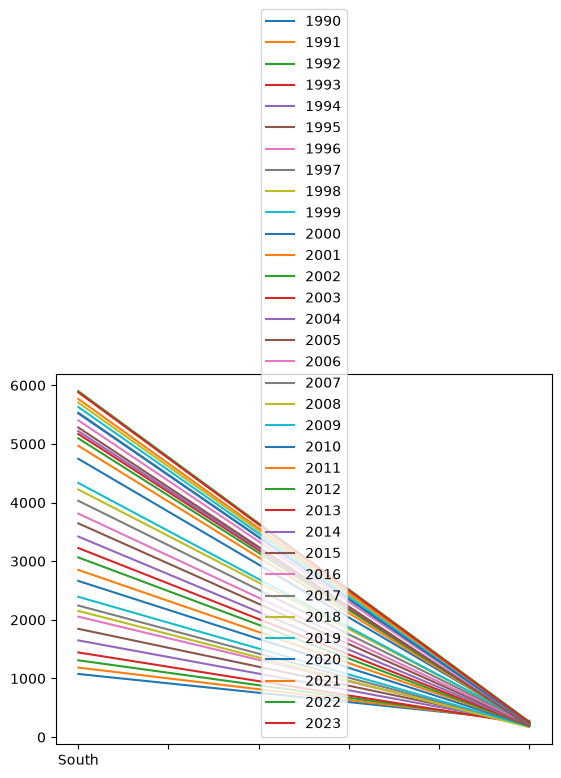

In [38]:
# 선그래프
df_sn.plot()

<Axes: >

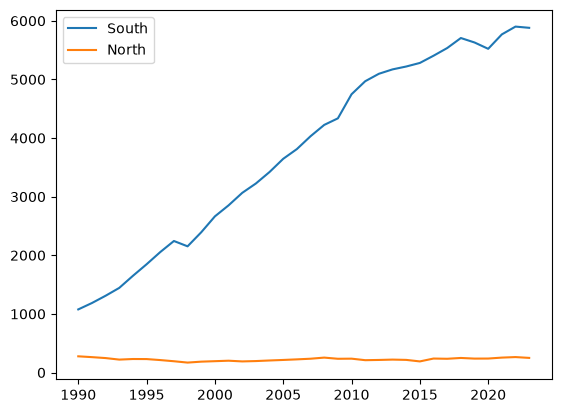

In [39]:
# 전치 하여 그리기
df_sn.T.plot()

<Axes: >

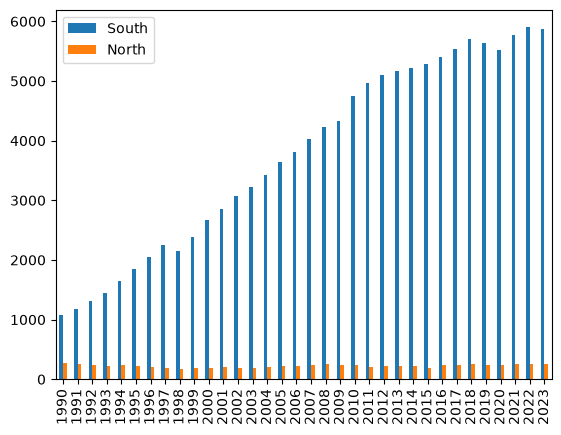

In [40]:
# 막대 그래프 그리기
df_sn.T.plot(
    kind='bar'
)

<Axes: ylabel='Frequency'>

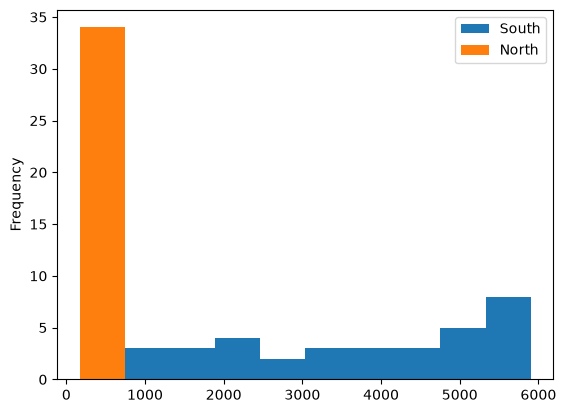

In [41]:
# 히스토그램
df_sn.T.plot(
    kind='hist'
)

In [42]:
# 산점도(산포도, 스캐터)
df = pd.read_csv("../Data/auto-mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


<Axes: xlabel='weight', ylabel='mpg'>

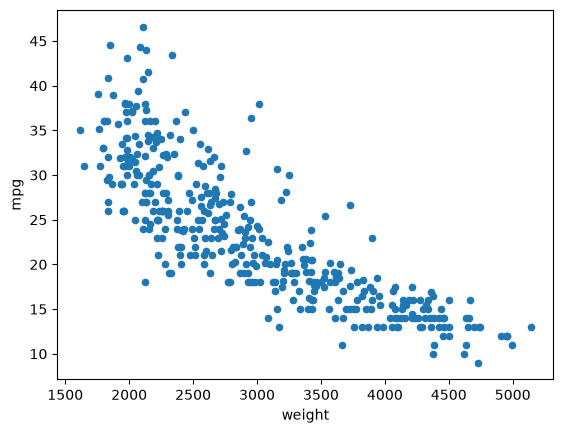

In [44]:
df.plot(
    x = 'weight',
    y = 'mpg',
    kind='scatter'
)

<Axes: >

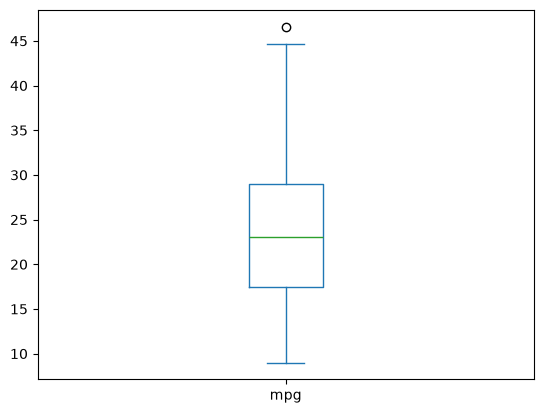

In [45]:
# 이상치 : 박스플롯(상자수염 그래프)
df.mpg.plot(
    kind='box'
)